In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

from ics26_rosenbrock import RESULTS_DIR

In [ ]:
ICS26_DIR = RESULTS_DIR / "ics26"
for d in ICS26_DIR.iterdir():
    print(d.name)

quadratic_v1_hessian_informed_split_experiments


In [ ]:
# Publication-Quality Plot Settings
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.figsize": (6.5, 4.5),
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "lines.linewidth": 1.5,
        "lines.markersize": 5,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
    }
)
PALETTE = "deep"
COLORS = sns.color_palette(PALETTE)

# Quadratic

In [ ]:
quadratic_dir = ICS26_DIR / "quadratic_v1_hessian_informed_split_experiments"
csv_path = quadratic_dir / "summary.csv"

df_q = pd.read_csv(csv_path)

In [ ]:
list(df_q.columns)

['problem_name',
 'problem_tag',
 'tol',
 'dim',
 'n_train',
 'n_test',
 'n_clusters',
 'ptwise_max_rel_error_linf',
 'ptwise_median_rel_error_linf',
 'l2_relative_error',
 'l2_abs_error',
 'n_out',
 'perct_out',
 'n_in',
 'n_in_good',
 'perct_in_good',
 'n_in_bad',
 'perct_in_bad',
 'train_time_sec',
 'predict_time_sec',
 'error_tag',
 'num_levels',
 'ERROR_SCALING_METHOD',
 'CLUSTER_SPLITTING_METHOD',
 'N_INIT_CLUSTERS',
 'N_MIN_PER_CLUSTER',
 'K_NEIGHBOURS',
 'ENFORCE_CONTAINMENT',
 'CONTAINMENT_LEVEL',
 'Q_SHRINK',
 'SYNTH_BUDGET_FACTOR',
 'CLUSTERING_VERSION',
 'USE_HESSIAN_INFORMED_SPLIT']

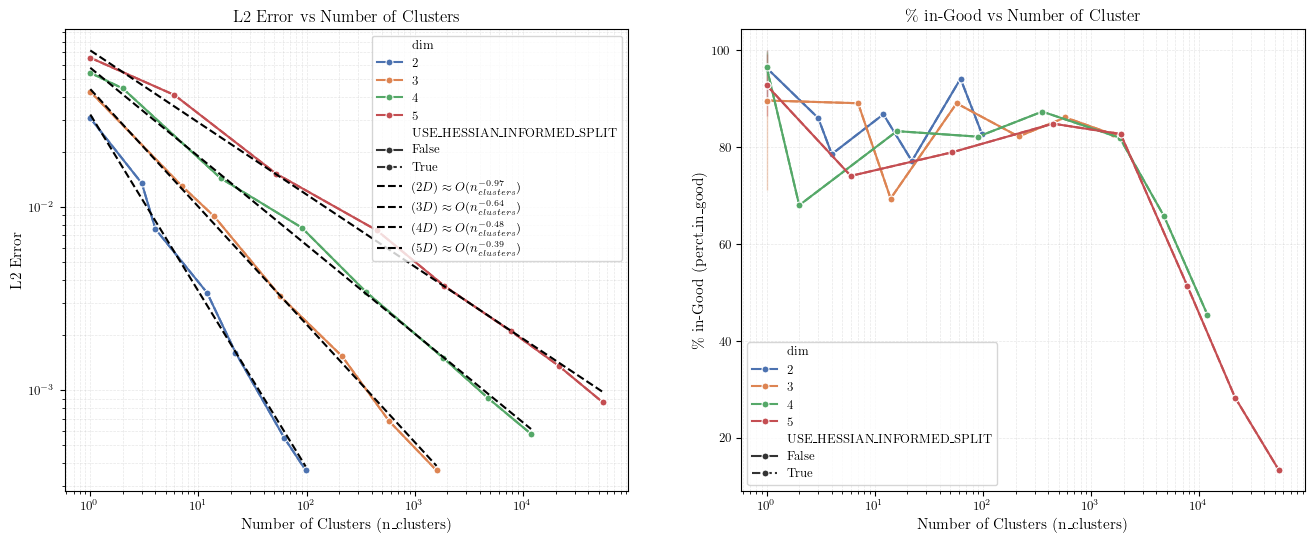

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_q,
    x="n_clusters",
    y="l2_relative_error",
    hue="dim",
    style="USE_HESSIAN_INFORMED_SPLIT",
    marker="o",
    palette=PALETTE,
)
# Fit linear regression lines (in log-log space) for each dimension
for dim in df_q["dim"].unique():
    subset = df_q[df_q["dim"] == dim]
    X = np.log(subset["n_clusters"].values).reshape(-1, 1)
    y = np.log(subset["l2_relative_error"].values)
    # Drop the last point to avoid outlier influence
    X = X[:-1]
    y = y[:-1]
    model = LinearRegression()
    model.fit(X, y)
    x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    label = rf"$({dim}D) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
    plt.plot(np.exp(x_fit), np.exp(y_fit), linestyle="--", color="k", label=label)
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel("L2 Error")
plt.title("L2 Error vs Number of Clusters")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_q,
    x="n_clusters",
    y="perct_in_good",
    hue="dim",
    style="USE_HESSIAN_INFORMED_SPLIT",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel(r"$\%$ in-Good (perct_in_good)")
plt.title(r"$\%$ in-Good vs Number of Cluster")
plt.grid(True, which="both", ls="--", lw=0.5)